In [23]:
import json
from pathlib import Path

In [24]:
# Path to your downloaded MPChat SI file
mpchat_si_path = Path("./mpchat/mpchat_si.json")

In [25]:
dialogues = []
# Load the dataset
with open(mpchat_si_path, "r") as f:
    dialogues = json.load(f)

# Check the number of dialogues and inspect the first one
print(f"Loaded {len(dialogues)} dialogues")
print(json.dumps(dialogues[0], indent=2))

Loaded 3 dialogues


KeyError: 0

In [26]:
# List top-level keys (e.g., 'train', 'val', 'test')
print(f"Top-level keys: {list(dialogues.keys())}")

# Peek into one of the sets
split = "train"  # or "val" / "test", depending on availability
sample = dialogues[split][0]

Top-level keys: ['train', 'val', 'test']


In [28]:
# Show one dialogue structure
import pprint
pprint.pprint(sample)

{'all_personas': [{'author': 'nickeymousee',
                   'created_utc': 1597599418.0,
                   'direct_url': 'https://i.imgur.com/q8eVRgR.jpg',
                   'file_name': 'iawlbw_q8eVRgR.jpg',
                   'id': 'iawlbw',
                   'permalink': '/r/barista/comments/iawlbw/i_wanted_to_share_a_couple_origami_dripper_art/',
                   'score': 5,
                   'subreddit': 'barista',
                   'title': 'i wanted to share a couple origami dripper art '
                            'pieces that i made into stickers recently!',
                   'url': 'https://imgur.com/a/XVJZgn7/'},
                  {'author': 'nickeymousee',
                   'created_utc': 1600533886.0,
                   'direct_url': 'https://i.redd.it/hhomxfpgv4o51.jpg',
                   'file_name': 'ivw0a1_hhomxfpgv4o51.jpg',
                   'id': 'ivw0a1',
                   'permalink': '/r/cat/comments/ivw0a1/i_made_some_fallinspired_black_cat_stic

In [29]:
from uuid import uuid4

# Choose split (train/val/test)
split = "train"
dialog_instances = []

for dialog in dialogues[split]:
    messages = dialog["messages"]
    authors = dialog["authors"]
    timestamps = dialog["created_utcs"]
    alice_id = dialog["main_author"]

    # Get all indices where Alice speaks
    alice_turns = [i for i, a in enumerate(authors) if a == alice_id]

    for idx in range(1, len(alice_turns)):
        # Current and previous Alice utterances
        curr_idx = alice_turns[idx]
        prev_idx = alice_turns[idx - 1]

        t_start = timestamps[prev_idx]
        t_end = timestamps[curr_idx]

        # Collect D-node utterances between t_start and t_end
        context = []
        for j, t in enumerate(timestamps):
            if t_start < t < t_end and authors[j] != alice_id:
                context.append({
                    "turn_index": j,
                    "speaker_id": authors[j],
                    "utterance": messages[j],
                    "sentiment_towards_target": None  # Placeholder
                })

        if context:
            s_node = {
                "turn_index": curr_idx,
                "speaker_id": alice_id,
                "utterance": messages[curr_idx]
            }
            dialog_instances.append({
                "dialog_id": str(uuid4()),  # unique ID for the instance
                "target_speaker": alice_id,
                "context": context,
                "s_node": s_node
            })

print(f"Extracted {len(dialog_instances)} valid dialogue instances.")


Extracted 7007 valid dialogue instances.


In [30]:
dialog_instances

[{'dialog_id': '6ee8654c-4189-49bf-b272-6c6f9a1cb99d',
  'target_speaker': 'nickeymousee',
  'context': [{'turn_index': 1,
    'speaker_id': 'stylofylo',
    'utterance': "omg i work at the cafe where we sell ur pins! they're so cute",
    'sentiment_towards_target': None}],
  's_node': {'turn_index': 2,
   'speaker_id': 'nickeymousee',
   'utterance': 'which cafe? i only have them at trueshot right now and in edmonton soon edit: saw a comment for hamilton haha, so cool'}},
 {'dialog_id': '57fb8901-322c-4086-bed7-2fcb74922cd6',
  'target_speaker': 'Soggypaper_',
  'context': [{'turn_index': 1,
    'speaker_id': 'TransparentCircle',
    'utterance': 'did you do that with nescafe?...',
    'sentiment_towards_target': None}],
  's_node': {'turn_index': 2,
   'speaker_id': 'Soggypaper_',
   'utterance': 'yes, i did hahaha'}},
 {'dialog_id': '8ebc5cbd-b6b5-40d3-99f2-80689a8b1a4d',
  'target_speaker': 'Soggypaper_',
  'context': [{'turn_index': 3,
    'speaker_id': 'TransparentCircle',
    '

In [31]:
import json

with open("dialog_instances.json", "w", encoding="utf-8") as f:
    json.dump(dialog_instances, f, ensure_ascii=False, indent=4)


In [10]:
import torch
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1

nli = pipeline(
    "text-classification",
    model="roberta-large-mnli",
    device=device
)

print("Pipeline loaded on device:", device)

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/1.43G [00:00<?, ?B/s]

D:\Research\ICML\UIG\Abstract_UIG\ICML_MP\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\vashi\.cache\huggingface\hub\models--roberta-large-mnli. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Some weights of the model checkpoint at roberta-large-mnli were not used when initializing RobertaForSequence

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Device set to use cuda:0


Pipeline loaded on device: 0


In [11]:
from tqdm import tqdm  # for progress bar

def classify_sentiment(premise, hypothesis):
    try:
        result = nli(f"{premise} </s> {hypothesis}")[0]["label"]
    except Exception:
        return "neutral"  # fallback on error
    if result == "ENTAILMENT":
        return "positive"
    elif result == "CONTRADICTION":
        return "negative"
    else:
        return "neutral"

# Apply sentiment classification to all context utterances
for instance in tqdm(dialog_instances, desc="Classifying sentiments"):
    s_text = instance["s_node"]["utterance"]
    for ctx in instance["context"]:
        ctx_text = ctx["utterance"]
        ctx["sentiment_towards_target"] = classify_sentiment(s_text, ctx_text)


Classifying sentiments: 100%|██████████████████████████████████████████████████████| 7007/7007 [01:52<00:00, 62.21it/s]


#New Logic for sentiment analysis

In [41]:
import re
import numpy as np
from sentence_transformers import SentenceTransformer, util
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
nltk.download("vader_lexicon", quiet=True)

# --------------------
# Model Loading
# --------------------

sentiment_model = SentimentIntensityAnalyzer()
text_encoder = SentenceTransformer("all-MiniLM-L6-v2")

# --------------------
# Static Seed Lexicons
# --------------------

AGREEMENT_CUES = {
    "i agree", "you're right", "good point", "exactly", "true",
    "correct", "makes sense", "well said", "i appreciate",
    "thanks for", "glad you agree"
}

DISAGREEMENT_CUES = {
    "i disagree", "not true", "incorrect", "i don't think",
    "that's wrong", "you're mistaken", "i reject", "i deny", "i doubt"
}

CONTRASTIVE_MARKERS = {"but", "however", "though", "although", "yet", "still"}

DEFENSIVE_MARKERS = {
    "what i meant", "let me clarify", "to be clear",
    "you're missing", "that wasn't my point"
}

NEGATION_WORDS = {"not", "never", "no", "don't", "doesn't", "can't", "won't"}

# --------------------
# SBERT Lexicon Expansion
# --------------------

def embed_cues(cues):
    texts = list(cues)
    embeddings = text_encoder.encode(texts, convert_to_tensor=True)
    return texts, embeddings

AGREE_TEXTS, AGREE_EMB = embed_cues(AGREEMENT_CUES)
DISAGREE_TEXTS, DISAGREE_EMB = embed_cues(DISAGREEMENT_CUES)
DEFENSIVE_TEXTS, DEFENSIVE_EMB = embed_cues(DEFENSIVE_MARKERS)

def semantic_match(clause, cue_embeddings, threshold=0.65):
    clause_emb = text_encoder.encode(clause, convert_to_tensor=True)
    sims = util.cos_sim(clause_emb, cue_embeddings)
    return sims.max().item() >= threshold

# --------------------
# Utility Functions
# --------------------

def contains_any(text, cues):
    return any(word in text for word in cues)

def split_into_clauses(text):
    return re.split(r"[.,;!?]", text)

# --------------------
# Hybrid Sentiment Inference
# --------------------

def infer_alice_sentiment_hybrid(d_nodes, s_node):
    alice_text = s_node["utterance"].lower()
    alice_clauses = split_into_clauses(alice_text)

    alice_embedding = text_encoder.encode(alice_text, convert_to_tensor=True)
    alice_sentiment_score = sentiment_model.polarity_scores(alice_text)["compound"]

    if not d_nodes:
        return []

    d_node = d_nodes[-1]  # recency bias
    d_text = d_node["utterance"].lower()
    d_embedding = text_encoder.encode(d_text, convert_to_tensor=True)

    pos_score = 0.0
    neg_score = 0.0

    # ---- Lexical + Semantic Signals ----
    for clause in alice_clauses:
        if semantic_match(clause, AGREE_EMB, threshold=0.65):
            pos_score += 2

        if semantic_match(clause, DISAGREE_EMB, threshold=0.65):
            neg_score += 2

        if semantic_match(clause, DEFENSIVE_EMB, threshold=0.60):
            neg_score += 2

        if contains_any(clause, CONTRASTIVE_MARKERS):
            neg_score += 1

        if contains_any(clause, NEGATION_WORDS):
            neg_score += 0.5

    # ---- VADER Polarity ----
    if alice_sentiment_score > 0.2:
        pos_score += 1
    elif alice_sentiment_score < -0.2:
        neg_score += 1

    # ---- Embedding Similarity ----
    sim = util.cos_sim(alice_embedding, d_embedding).item()
    if sim > 0.4:
        pos_score += 0.5
    elif sim < 0.1:
        neg_score += 0.5

    # ---- Final Decision ----
    sentiment = "positive" if pos_score > neg_score else "negative"

    d_node["sentiment_towards_target"] = sentiment
    d_node["debug"] = {
        "pos_score": pos_score,
        "neg_score": neg_score,
        "alice_sentiment": alice_sentiment_score,
        "similarity": sim
    }

    return [d_node]


In [42]:
from tqdm import tqdm  # for progress bar

for dialog in tqdm(dialog_instances):
    dialog["context"] = infer_alice_sentiment_hybrid(dialog["context"], dialog["s_node"])

100%|██████████████████████████████████████████████████████████████████████████████| 7007/7007 [16:50<00:00,  6.94it/s]


In [43]:
for sample in dialog_instances[:3]:
    print(json.dumps(sample, indent=2))


{
  "dialog_id": "6ee8654c-4189-49bf-b272-6c6f9a1cb99d",
  "target_speaker": "nickeymousee",
  "context": [
    {
      "turn_index": 1,
      "speaker_id": "stylofylo",
      "utterance": "omg i work at the cafe where we sell ur pins! they're so cute",
      "sentiment_towards_target": "positive",
      "debug": {
        "pos_score": 1.0,
        "neg_score": 0.5,
        "alice_sentiment": 0.7177,
        "similarity": 0.35043150186538696
      }
    }
  ],
  "s_node": {
    "turn_index": 2,
    "speaker_id": "nickeymousee",
    "utterance": "which cafe? i only have them at trueshot right now and in edmonton soon edit: saw a comment for hamilton haha, so cool"
  }
}
{
  "dialog_id": "57fb8901-322c-4086-bed7-2fcb74922cd6",
  "target_speaker": "Soggypaper_",
  "context": [
    {
      "turn_index": 1,
      "speaker_id": "TransparentCircle",
      "utterance": "did you do that with nescafe?...",
      "sentiment_towards_target": "positive",
      "debug": {
        "pos_score": 1.0,
 

In [44]:
import json

with open("mpchat_hybrid_sentiment_updated.json", "w") as f:
    for d in dialog_instances:
        json.dump(d, f)
        f.write("\n")


Total Dialog Instances: 7007
Average D-nodes per S-node: 1.00
Unique Users Involved: 10552

Sentiment Distribution:
  Positive: 4373
  Negative: 2634


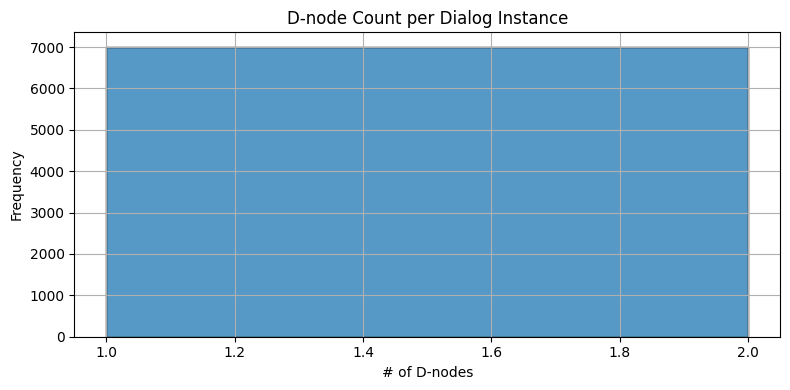

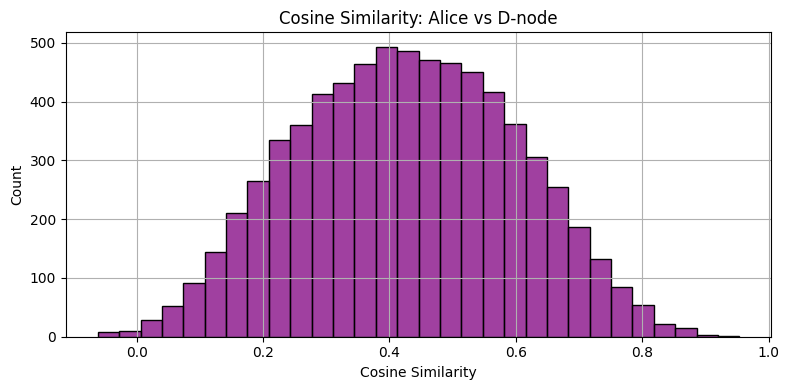


Sample Dialog:
{
  "dialog_id": "4f876b2b-f2f5-4600-ab69-c1b690784b67",
  "target_speaker": "fluffywhitething",
  "context": [
    {
      "turn_index": 2,
      "speaker_id": "Rabbiac",
      "utterance": "mine likes... . i'm not sure if he/she realise everyone can still see him/her",
      "sentiment_towards_target": "negative",
      "debug": {
        "pos_score": 1.0,
        "neg_score": 1.0,
        "alice_sentiment": 0.685,
        "similarity": 0.304606556892395
      }
    }
  ],
  "s_node": {
    "turn_index": 3,
    "speaker_id": "fluffywhitething",
    "utterance": "good hiding! mine is quickly outgrowing his/her pipe, but still squeezes in. tail is always sticking out. s/he also has a cave that is much better for hiding in. i have to shine a flashlight in it to make sure that's where s/he is."
  }
}


In [45]:
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import seaborn as sns
import json

# 1. Basic Stats
num_dialogs = len(dialog_instances)
avg_d_nodes = sum(len(d["context"]) for d in dialog_instances) / num_dialogs
all_speakers = set(d["target_speaker"] for d in dialog_instances)
all_speakers |= {c["speaker_id"] for d in dialog_instances for c in d["context"]}

print(f"Total Dialog Instances: {num_dialogs}")
print(f"Average D-nodes per S-node: {avg_d_nodes:.2f}")
print(f"Unique Users Involved: {len(all_speakers)}")

# 2. Sentiment Distribution
sentiment_counter = Counter()
for d in dialog_instances:
    for c in d["context"]:
        sentiment_counter[c["sentiment_towards_target"]] += 1

print("\nSentiment Distribution:")
for s, count in sentiment_counter.items():
    print(f"  {s.capitalize()}: {count}")

# 3. D-node Count Distribution
dnode_counts = [len(d["context"]) for d in dialog_instances]
plt.figure(figsize=(8, 4))
sns.histplot(dnode_counts, bins=range(1, max(dnode_counts)+2), kde=False)
plt.title("D-node Count per Dialog Instance")
plt.xlabel("# of D-nodes")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Debug Score Ranges (Optional)
debug_scores = defaultdict(list)
for d in dialog_instances:
    for c in d["context"]:
        if "debug" in c:
            dbg = c["debug"]
            debug_scores["pos_score"].append(dbg["pos_score"])
            debug_scores["neg_score"].append(dbg["neg_score"])
            debug_scores["similarity"].append(dbg["similarity"])
            debug_scores["alice_sentiment"].append(dbg["alice_sentiment"])

# Plot sentiment similarity distribution
plt.figure(figsize=(8, 4))
sns.histplot(debug_scores["similarity"], bins=30, color="purple")
plt.title("Cosine Similarity: Alice vs D-node")
plt.xlabel("Cosine Similarity")
plt.ylabel("Count")
plt.grid(True)
plt.tight_layout()
plt.show()

# 5. Spot-check random example
import random
print("\nSample Dialog:")
sample = random.choice(dialog_instances)
print(json.dumps(sample, indent=2))
